In [1]:
import numpy as np
import matplotlib.pyplot as plt
%config InlineBackend.figure_formats = ['svg']
from scipy.linalg import sqrtm
from concurrent.futures import ProcessPoolExecutor, as_completed

In [2]:
plt.rcParams.update({'font.size': 14})
plt.rcParams["figure.figsize"] = (7,5)
import seaborn as sns
colors = sns.color_palette("colorblind")

In [3]:
# Define custom dash patterns for each line without names
custom_dashes = [
    (1, 0),           # Solid
    (1, 1),           # Dotted
    (4, 2),           # Dashed
    (3, 2, 1, 2),     # Dash-Dot
    (5, 2, 1, 2, 1, 2),  # Dash-Dot-Dot
    (8, 2),           # Long Dashes
    (2, 4),           # Loosely Dashed
    (5, 4, 1, 4),     # Sparse Dash-Dot
    (6, 4, 1, 4, 1, 4),  # Sparse Dash-Dot-Dot
    (1, 4),           # Loosely Dotted
    (4, 2, 1, 2, 1, 2),  # Dashed with Dots
    (2, 4, 1, 4, 2, 4)   # Custom Pattern 1
]

In [4]:
c = 1
landa = 1.0
def cost(x): return 0.5*x.T@H@x + 0.25*landa*(np.sum(x**4)) - c*(1/3)*landa*(np.sum(x**3))
def g(x): return H@x + landa*x**3 - c*landa*x**2

In [5]:
def sqrtmE(X):
    """
    Computes the square root of M = X @ X.T using the SVD-based method.
    
    Parameters:
    X : numpy.ndarray
        The input matrix X.

    Returns:
    numpy.ndarray
        The square root of M, where M = X @ X.T.
    """
    # Perform SVD on X
    U, Sigma, Vt = np.linalg.svd(X, full_matrices=False)
    
    # Compute the square root of the diagonal matrix
    sqrt_Sigma = np.sqrt(Sigma)
    
    # Construct the square root of M using U, sqrt(Sigma), and U.T
    sqrt_M = U @ np.diag(sqrt_Sigma) @ U.T
    
    return sqrt_M

In [6]:
def CSGD_Traj(eta, x0, nit, sigma, seed):
    np.random.seed(seed)
    x = np.zeros((nit, d))
    f = np.zeros((nit,))
    x[0] = x0
    f[0] = cost(x[0])
    
    for k in range(nit-1):
        # Compute the gradient at x[k]
        grads = g(x[k])
        
        # Create a matrix with num_columns copies of grads (shape: (d, num_columns))
        grad_matrix = np.tile(grads, (N, 1)).T
        
        # Add noise separately to each column of grad_matrix
        noise = sigma * np.random.normal(size=(d, N))
        grad_matrix += noise
        
        # Drop kappa components from each column
        for col in range(N):
            dropped_indices = np.random.choice(d, kappa, replace=False)
            grad_matrix[dropped_indices, col] = 0
        
        # Average the matrix over the columns
        avg_grads = np.mean(grad_matrix, axis=1)
        
        # Update the position using the averaged gradient
        x[k+1] = x[k] - eta * (d / (d-kappa)) * avg_grads

        
        # Compute the cost at the new position
        f[k+1] = cost(x[k+1])
    
    return x, f.reshape(f.shape[-1], 1)


In [7]:
def CSGD_SDE_Traj(eta, x0, nit, sigma, seed):
    np.random.seed(seed)
    x = np.zeros((nit, d))
    f = np.zeros((nit,))
    x[0] = x0
    f[0] = cost(x[0])
    
    for k in range(nit-1):
        # Compute the gradient at x[k]
        grads = g(x[k])
        
        # Add noise separately to each column of grad_matrix
        noise = np.random.normal(size=(d, 1))
        
        M = Omega*grads@grads.T + (Omega+1)*sigma**2*np.eye(d)

        
        # Update the position using the averaged gradient
        x[k+1] = x[k] - eta * (grads+(1/np.sqrt(N)*sqrtmE(M)@noise).reshape(d,))
    
        
        # Compute the cost at the new position
        f[k+1] = cost(x[k+1])
    
    return x, f.reshape(f.shape[-1], 1)


In [8]:
d = 2
H = np.array([[-1.0, 0.0],[0.0, 2.0]])
eta = 0.01
sigma = 10

kappa=1

Omega = d/(d-kappa)-1

T=100
nit= int(T/eta)

N=10

np.random.seed(0)

x0 = -0.75*np.random.normal(size=(d,)) #-0.5*np.random.normal(size=(d,))

In [9]:
Omega

1.0

In [10]:
def run_CSGD_Traj_in_parallel():
    num_tasks = 5000
    Trajectories = []

    seeds = range(num_tasks)  # Different seed for each task

    # Create a ProcessPoolExecutor with as many workers as you have CPU cores
    with ProcessPoolExecutor() as executor:
        # Submit all tasks to the executor
        futures = [executor.submit(CSGD_Traj, eta, x0, nit, sigma, seed) for seed in seeds]

        # As each task completes, add the result to the results list
        for i, future in enumerate(as_completed(futures), 1):
            result = future.result()
            Trajectories.append(result[0])

    return Trajectories

In [11]:
def run_CSGD_SDE_Traj_in_parallel():
    num_tasks = 5000

    Trajectories = []


    seeds = range(num_tasks)  # Different seed for each task

    # Create a ProcessPoolExecutor with as many workers as you have CPU cores
    with ProcessPoolExecutor() as executor:
        # Submit all tasks to the executor
        futures = [executor.submit(CSGD_SDE_Traj, eta, x0, nit, sigma, seed) for seed in seeds]

        # As each task completes, add the result to the results list
        for i, future in enumerate(as_completed(futures), 1):
            result = future.result()
            
            Trajectories.append(result[0])



    return Trajectories

In [12]:
if __name__ == "__main__":
    Trajectories = run_CSGD_Traj_in_parallel()
    print("All tasks completed.")

All tasks completed.


In [13]:
if __name__ == "__main__":
    Trajectories_SDE = run_CSGD_SDE_Traj_in_parallel()
    print("All tasks completed.")

All tasks completed.


In [14]:
array_Trajectories = np.array(Trajectories)
avg_traj = np.mean(array_Trajectories,axis=0)

In [15]:
array_Trajectories_SDE = np.array(Trajectories_SDE)
avg_traj_SDE = np.mean(array_Trajectories_SDE,axis=0)

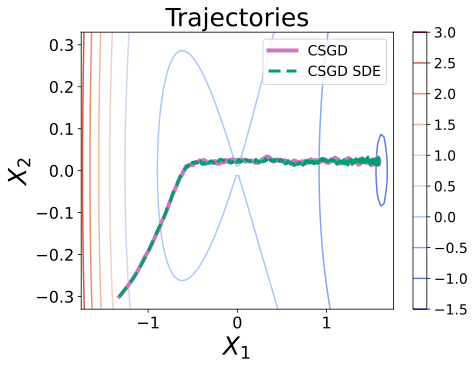

In [16]:
max_x = np.max(np.abs(avg_traj[:,0]))*1.1
max_y = np.max(np.abs(avg_traj[:,1]))*1.1
x_values = np.linspace(-max_x, max_x, 100)
y_values = np.linspace(-max_y, max_y, 100)
X, Y = np.meshgrid(x_values, y_values)
Z = np.zeros_like(X)

for i in range(X.shape[0]):
    for j in range(X.shape[1]):
        Z[i, j] = cost(np.array([X[i, j], Y[i, j]]))
plt.contour(X, Y, Z, cmap='coolwarm')  # Adjust the colormap ('cmap') as needed
plt.colorbar()  # Add a colorbar to show the values
line_1, = plt.plot(avg_traj[:,0], avg_traj[:,1], color = colors[4],linewidth=4)
line_2, = plt.plot(avg_traj_SDE[:,0], avg_traj_SDE[:,1], color = colors[2],linewidth=3, dashes=custom_dashes[2])

plt.xlim([-max_x, max_x])
plt.ylim([-max_y, max_y])

plt.legend([line_1, line_2], ['CSGD','CSGD SDE'],fontsize=14)

plt.title("Trajectories",fontsize=25)
plt.xlabel(r'$X_1$',fontsize=25)
plt.ylabel(r'$X_2$',fontsize=25)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
namefile = "CSGD_EmbeddedSaddle_Final" + ".pdf"
plt.savefig(namefile, bbox_inches='tight', dpi=1000)
plt.show()